# Entendimiento de los datos

## Descarga de los datos desde Drive

In [27]:
import os
import glob
import shutil
from concurrent.futures import ThreadPoolExecutor
from google.colab import drive
import dask.dataframe as dd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import numpy as np
import pandas as pd
import dask
import dask.array as da
import matplotlib.pyplot as plt

# 1. Montar Google Drive localmente en el entorno de Colab
print("[PROCESO] Montando Google Drive...")
drive.mount('/content/drive')


[PROCESO] Montando Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# 2. Configurar rutas de origen (Drive) y destino (local)
# Ajusta 'MyDrive' o 'Mi unidad' según la estructura de tu Drive
drive_source_folder = '/content/drive/MyDrive/Superintendencia/dataset_modelo_v4'
local_destination_folder = './dataset_modelo_v4'

# Crear la carpeta local de destino si no existe
os.makedirs(local_destination_folder, exist_ok=True)

# 3. Buscar todos los archivos .parquet en Drive
files_to_download = glob.glob(os.path.join(drive_source_folder, '*.parquet'))
print(f"[INFO] Se encontraron {len(files_to_download)} archivos para descargar.")

# 4. Función para copiar un archivo individual de Drive a local
def copiar_archivo(file_path):
    try:
        filename = os.path.basename(file_path)
        dest_path = os.path.join(local_destination_folder, filename)

        # Evitar sobreescribir si el archivo ya existe localmente
        if not os.path.exists(dest_path):
            shutil.copy2(file_path, dest_path)
        return True
    except Exception as e:
        print(f"[ERROR] Error al copiar {os.path.basename(file_path)}: {e}")
        return False

# 5. Ejecutar la copia masiva en paralelo usando hilos
print("[PROCESO] Iniciando descarga paralela desde Google Drive...")
max_workers = 12  # Ajusta el número de hilos según rendimiento
with ThreadPoolExecutor(max_workers=max_workers) as executor:
    resultados = list(executor.map(copiar_archivo, files_to_download))

exitosos = sum(1 for r in resultados if r)
print(f"\n[ÉXITO] ¡Proceso finalizado! Se descargaron {exitosos}/{len(files_to_download)} archivos desde Google Drive.")

[INFO] Se encontraron 1281 archivos para descargar.
[PROCESO] Iniciando descarga paralela desde Google Drive...

[ÉXITO] ¡Proceso finalizado! Se descargaron 1281/1281 archivos desde Google Drive.


In [11]:
print("[PROCESO] Cargando dataset con Dask...")
# Leer todos los archivos Parquet dentro de la carpeta de manera paralela y perezosa
df = dd.read_parquet(f"{local_destination_folder}/*.parquet")

print("[ÉXITO] Datos cargados en un DataFrame de Dask de forma exitosa.")
print("\nEstructura del DataFrame (Lazy Evaluation):")
print(df)

[PROCESO] Cargando dataset con Dask...
[ÉXITO] Datos cargados en un DataFrame de Dask de forma exitosa.

Estructura del DataFrame (Lazy Evaluation):
Dask DataFrame Structure:
                               PERIODO    MES NIU_USUARIO ID_MERCADO COD_CIRCUITO_LINEA COD_TRANSFORMADOR DANE_NIU UBICACION ESTRATO_SECTOR NIVEL_TENSION TIPO_CONEXION AUTOGENERADOR TIPO_MEDIDOR DIAS_FACTURADOS CONSUMO_KWH PROM_SEM_BENCHMARK CONS_SUBSIST NRO_FAMILIAS DIAS_MORA ENE_EXPORT CONS_RECUP FECHA_LECTURA FECHA_FACTURA  KWH_DIA CAMBIO_TRAFO CAMBIO_ESTRATO CAMBIO_MEDIDOR KWH_DIA_LAG1 KWH_DIA_LAG2 KWH_DIA_LAG3 KWH_DIA_LAG12 KWH_DIA_MM3 KWH_DIA_MM6 KWH_DIA_STD6 KWH_DIA_MM12 PCT_CEROS_PREVIOS MESES_HIST_12 MESES_DESDE_CAMBIO
npartitions=1281                                                                                                                                                                                                                                                                                   

In [12]:
df.head()

,PERIODO,MES,NIU_USUARIO,ID_MERCADO,COD_CIRCUITO_LINEA,COD_TRANSFORMADOR,DANE_NIU,UBICACION,ESTRATO_SECTOR,NIVEL_TENSION,...,KWH_DIA_LAG2,KWH_DIA_LAG3,KWH_DIA_LAG12,KWH_DIA_MM3,KWH_DIA_MM6,KWH_DIA_STD6,KWH_DIA_MM12,PCT_CEROS_PREVIOS,MESES_HIST_12,MESES_DESDE_CAMBIO
0,2022-08-01,8,647531E1C84ACD346734D88936E1713863CB0E6CD45C4A...,176,1098,100BHC0000,11001000,2,3,1,...,6.107143,5.866667,NaN,5.708442,5.359684,0.559685,5.255919,0.000000,7,6.0
1,2022-08-01,8,660698821D76D3F32683262F722720B8994BD22A483C2F...,176,0934,100BOY0000,11001000,2,3,1,...,2.310345,2.633333,NaN,2.425670,2.628853,0.339358,2.573649,0.000000,7,6.0
2,2022-08-01,8,406DF9EBEAF15F605EB482C3C978071D74921FBAE3BF39...,176,1232,100BA70000,11001000,2,1,1,...,2.586207,2.562500,NaN,2.582902,2.256968,0.375421,2.133679,0.000000,7,6.0
3,2022-08-01,8,296BCF2EA334EAD5C4002A0C80B6A93ED6DA5BB52B31CB...,176,0933,100B5W0000,11001000,2,2,1,...,2.965517,2.812500,NaN,2.774491,2.617951,0.397879,2.546989,0.000000,7,6.0
4,2022-08-01,8,ECAEB6DEF85328C6A89A3F35D6EE1228EABA1DF7194E82...,176,0362,100BN90000,11001000,2,1,1,...,0.071429,0.800000,NaN,0.573304,0.521746,0.379998,0.447211,0.142857,7,6.0


## Revisión Peliminar de los datos

In [13]:
# --- Definición de Umbrales ---
UMBRAL_NULOS = 0.50             # Porcentaje de nulos a considerar (50% o más)
UMBRAL_CARDINALIDAD = 50        # Número de categorías únicas a considerar "alta cardinalidad"
UMBRAL_DESBALANCE = 0.95        # Porcentaje de la categoría más frecuente para considerarla desbalanceada (95% o más)

# --- Inicialización de Listas de Resultados ---
nulos_altos = []
alta_cardinalidad = []
desbalance_categorias = []

# Calculamos la longitud total una sola vez
total_rows = len(df)

# --- Análisis por Columna ---
for col in df.columns:
    print(f"Procesando columna: {col}...")

    # 1. Porcentaje de Nulos (calculado con .compute())
    nulos_sum = df[col].isnull().sum().compute()
    porc_nulos = nulos_sum / total_rows

    if porc_nulos >= UMBRAL_NULOS:
        nulos_altos.append((col, porc_nulos * 100)) # Almacena nombre y porcentaje

    # 2. Análisis de Cardinalidad y Desbalance (para columnas con potencial de ser categóricas)
    # Se evalúan columnas 'object' y aquellas con pocos valores únicos
    if df[col].dtype == 'object' or df[col].dtype == 'string':
        # Para evitar calcular repetidas veces, calculamos el número de valores únicos con .compute()
        n_unicos = df[col].nunique().compute()

        # Evaluar Alta Cardinalidad (más de 50 categorías)
        if n_unicos > UMBRAL_CARDINALIDAD:
            alta_cardinalidad.append((col, n_unicos)) # Almacena nombre y conteo único

        # Evaluar Desbalance (solo si hay más de una categoría)
        elif n_unicos > 1:
            # Conteo de la categoría más frecuente (usamos compute() para obtener la serie de Pandas real)
            value_counts_pd = df[col].value_counts().compute()
            if len(value_counts_pd) > 0:
                conteo_max = value_counts_pd.iloc[0] / value_counts_pd.sum()

                if conteo_max >= UMBRAL_DESBALANCE:
                    cat_dominante = value_counts_pd.index[0]
                    desbalance_categorias.append((col, conteo_max * 100, cat_dominante)) # Nombre, %, dominante

print(f"\n1. Columnas con ALTO PORCENTAJE DE NULOS (>= {UMBRAL_NULOS*100:.0f}%):")
if nulos_altos:
    for col, porc in nulos_altos:
        print(f"   - '{col}': {porc:.2f}% nulos")
else:
    print("   -> Ninguna columna supera el umbral de nulos.")

print(f"\n2. Columnas con ALTA CARDINALIDAD (>{UMBRAL_CARDINALIDAD} categorías únicas):")
if alta_cardinalidad:
    for col, n_unicos in alta_cardinalidad:
        print(f"   - '{col}': {n_unicos} valores únicos")
else:
    print("   -> Ninguna columna tiene alta cardinalidad (según el umbral definido).")

print(f"\n3. Columnas con DESBALANCE EXTREMO (categoría dominante >= {UMBRAL_DESBALANCE*100:.0f}%):")
if desbalance_categorias:
    for col, porc, cat in desbalance_categorias:
        print(f"   - '{col}': {porc:.2f}% domina (Categoría: '{cat}')")
else:
    print("   -> Ninguna columna presenta desbalance extremo.")

print("\n" + "=" * 60)

Procesando columna: PERIODO...
Procesando columna: MES...
Procesando columna: NIU_USUARIO...
Procesando columna: ID_MERCADO...
Procesando columna: COD_CIRCUITO_LINEA...
Procesando columna: COD_TRANSFORMADOR...
Procesando columna: DANE_NIU...
Procesando columna: UBICACION...
Procesando columna: ESTRATO_SECTOR...
Procesando columna: NIVEL_TENSION...
Procesando columna: TIPO_CONEXION...
Procesando columna: AUTOGENERADOR...
Procesando columna: TIPO_MEDIDOR...
Procesando columna: DIAS_FACTURADOS...
Procesando columna: CONSUMO_KWH...
Procesando columna: PROM_SEM_BENCHMARK...
Procesando columna: CONS_SUBSIST...
Procesando columna: NRO_FAMILIAS...
Procesando columna: DIAS_MORA...
Procesando columna: ENE_EXPORT...
Procesando columna: CONS_RECUP...
Procesando columna: FECHA_LECTURA...
Procesando columna: FECHA_FACTURA...
Procesando columna: KWH_DIA...
Procesando columna: CAMBIO_TRAFO...
Procesando columna: CAMBIO_ESTRATO...
Procesando columna: CAMBIO_MEDIDOR...
Procesando columna: KWH_DIA_LAG1..

In [14]:
# 1. Limpieza rápida de la columna TIPO_MEDIDOR en Dask usando mapeo de caracteres corruptos
replacements = {
    'ElectrÃ³nico': 'Electrónico',
    'ElectromecÃ¡nico': 'Electromecánico'
}

# Aplicamos la limpieza de forma perezosa en Dask si la columna existe
if 'TIPO_MEDIDOR' in df.columns:
    df['TIPO_MEDIDOR'] = df['TIPO_MEDIDOR'].replace(replacements)

columnas_numericas_categoricas = ['ID_MERCADO', 'ESTRATO_SECTOR', 'NIVEL_TENSION', 'TIPO_CONEXION', 'AUTOGENERADOR', 'TIPO_MEDIDOR']

print("Analizando desbalance en variables categóricas (Corregido y Ordenado Descendente):")
for col in columnas_numericas_categoricas:
    if col in df.columns:
        # Obtenemos la distribución de frecuencias real
        conteo = df[col].value_counts().compute()

        # ¡Paso clave! Ordenamos explícitamente de mayor a menor frecuencia
        conteo = conteo.sort_values(ascending=False)

        total = conteo.sum()

        if total > 0 and len(conteo) > 0:
            # Ahora sí, el índice 0 es garantizado el más frecuente (dominante)
            categoria_dominante = conteo.index[0]
            frecuencia_maxima = conteo.iloc[0]
            pct_max = (frecuencia_maxima / total) * 100

            print(f"- '{col}':")
            print(f"   Categoría dominante: '{categoria_dominante}'")
            print(f"   Frecuencia: {frecuencia_maxima:,} de {total:,} registros ({pct_max:.2f}%)")
            print(f"   Categorías únicas encontradas (después de limpieza si aplica): {len(conteo)}")
            if len(conteo) > 1:
                print(f"   Distribución completa:\n{conteo.to_string()}")
            print("")

Analizando desbalance en variables categóricas (Corregido y Ordenado Descendente):
- 'ID_MERCADO':
   Categoría dominante: '176'
   Frecuencia: 109,345,545 de 109,345,545 registros (100.00%)
   Categorías únicas encontradas (después de limpieza si aplica): 1

- 'ESTRATO_SECTOR':
   Categoría dominante: '3'
   Frecuencia: 38,964,931 de 109,345,545 registros (35.63%)
   Categorías únicas encontradas (después de limpieza si aplica): 6
   Distribución completa:
ESTRATO_SECTOR
3    38964931
2    37182947
4    15740840
1     8353255
5     5111758
6     3991814

- 'NIVEL_TENSION':
   Categoría dominante: '1'
   Frecuencia: 109,345,011 de 109,345,545 registros (100.00%)
   Categorías únicas encontradas (después de limpieza si aplica): 2
   Distribución completa:
NIVEL_TENSION
1    109345011
2          534

- 'TIPO_CONEXION':
   Categoría dominante: '2'
   Frecuencia: 109,345,545 de 109,345,545 registros (100.00%)
   Categorías únicas encontradas (después de limpieza si aplica): 1

- 'AUTOGENER

## Análisis descriptivo de los datos

In [16]:
# ============================================================
# Clasificación de variables según el esquema de BigQuery
# ============================================================

# Llaves / identificadores (no se usan como features)
cols_id = ['PERIODO', 'NIU_USUARIO']

# Variable objetivo
col_target = 'KWH_DIA'

# Benchmark (línea base a superar, no es feature)
col_benchmark = 'PROM_SEM_BENCHMARK'

# Excluidas: leakage directo o fechas en texto
cols_excluir = [
    'CONSUMO_KWH',     # target = CONSUMO_KWH / DIAS_FACTURADOS → leakage directo
    'FECHA_LECTURA',   # texto dd/mm/aa
    'FECHA_FACTURA',   # texto dd/mm/aa
]

# Categóricas (códigos, banderas y proxies espaciales, aunque vengan como INTEGER)
cols_categoricas = [
    'MES',                 # estacionalidad (1-12)
    'ID_MERCADO',
    'COD_CIRCUITO_LINEA',
    'COD_TRANSFORMADOR',   # alta cardinalidad
    'DANE_NIU',
    'UBICACION',
    'ESTRATO_SECTOR',      # ordinal (1-6)
    'NIVEL_TENSION',
    'TIPO_CONEXION',
    'AUTOGENERADOR',
    'TIPO_MEDIDOR',
    'CONS_SUBSIST',
    'CAMBIO_TRAFO',        # binaria
    'CAMBIO_ESTRATO',      # binaria
    'CAMBIO_MEDIDOR',      # binaria
]

# Numéricas continuas / de conteo
cols_numericas = [
    'DIAS_FACTURADOS',
    'NRO_FAMILIAS',
    'DIAS_MORA',           # posible leakage (contemporáneo)
    'ENE_EXPORT',          # posible leakage (contemporáneo)
    'CONS_RECUP',          # posible leakage (contemporáneo)
    'KWH_DIA_LAG1', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12',
    'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_MM12', 'KWH_DIA_STD6',
    'PCT_CEROS_PREVIOS',
    'MESES_HIST_12',
    'MESES_DESDE_CAMBIO',  # NULL = sin cambio observado, no imputar con 0
]

# ------------------------------------------------------------
# Verificación: que no falte ni sobre ninguna columna
# ------------------------------------------------------------
clasificadas = cols_id + [col_target, col_benchmark] + cols_excluir + cols_categoricas + cols_numericas
sin_clasificar = set(df.columns) - set(clasificadas)
inexistentes   = set(clasificadas) - set(df.columns)
duplicadas     = {c for c in clasificadas if clasificadas.count(c) > 1}

print(f"[INFO] Columnas en df: {len(df.columns)}")
print(f"[INFO] Categóricas: {len(cols_categoricas)} | Numéricas: {len(cols_numericas)}")
print(f"[CHECK] Sin clasificar: {sin_clasificar or 'ninguna'}")
print(f"[CHECK] No existen en df: {inexistentes or 'ninguna'}")
print(f"[CHECK] Duplicadas: {duplicadas or 'ninguna'}")

# Subconjuntos listos para el análisis de calidad
df_cat = df[cols_categoricas]
df_num = df[cols_numericas + [col_target, col_benchmark]]


[INFO] Columnas en df: 38
[INFO] Categóricas: 15 | Numéricas: 16
[CHECK] Sin clasificar: ninguna
[CHECK] No existen en df: ninguna
[CHECK] Duplicadas: ninguna


### Variables Cuantitativas

In [ ]:
pd.set_option("display.float_format", "{:,.2f}".format)

df[cols_numericas].describe().compute().T

,count,mean,std,min,25%,50%,75%,max
DIAS_FACTURADOS,"109,345,545.00",30.44,1.69,1.00,30.00,31.00,33.00,186.00
NRO_FAMILIAS,"107,089,046.00",0.00,0.02,0.00,0.00,0.00,0.00,9.00
DIAS_MORA,"109,345,545.00",1.56,48.89,0.00,0.00,0.00,0.00,"7,908.00"
ENE_EXPORT,"109,345,545.00",0.00,10.96,0.00,0.00,0.00,0.00,"112,810.00"
CONS_RECUP,"109,345,545.00",0.00,1.26,0.00,0.00,0.00,0.00,"10,972.00"
KWH_DIA_LAG1,"106,886,141.00",4.62,14.09,0.00,2.56,4.07,6.46,"97,026.21"
KWH_DIA_LAG2,"104,441,811.00",4.62,13.75,0.00,2.58,4.10,6.52,"97,026.21"
KWH_DIA_LAG3,"102,006,714.00",4.62,14.40,0.00,2.58,4.16,6.55,"97,026.21"
KWH_DIA_LAG12,"80,442,611.00",4.67,15.16,0.00,2.59,4.10,6.56,"97,026.21"
KWH_DIA_MM3,"106,926,771.00",4.61,10.93,0.00,2.60,4.09,6.46,"32,396.16"


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


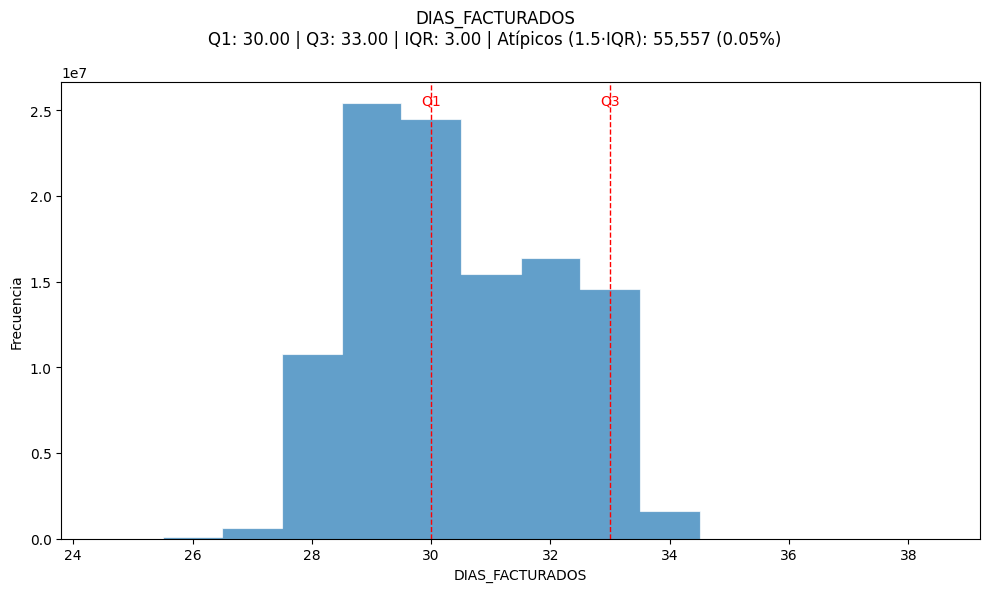

[OK] DIAS_FACTURADOS guardado


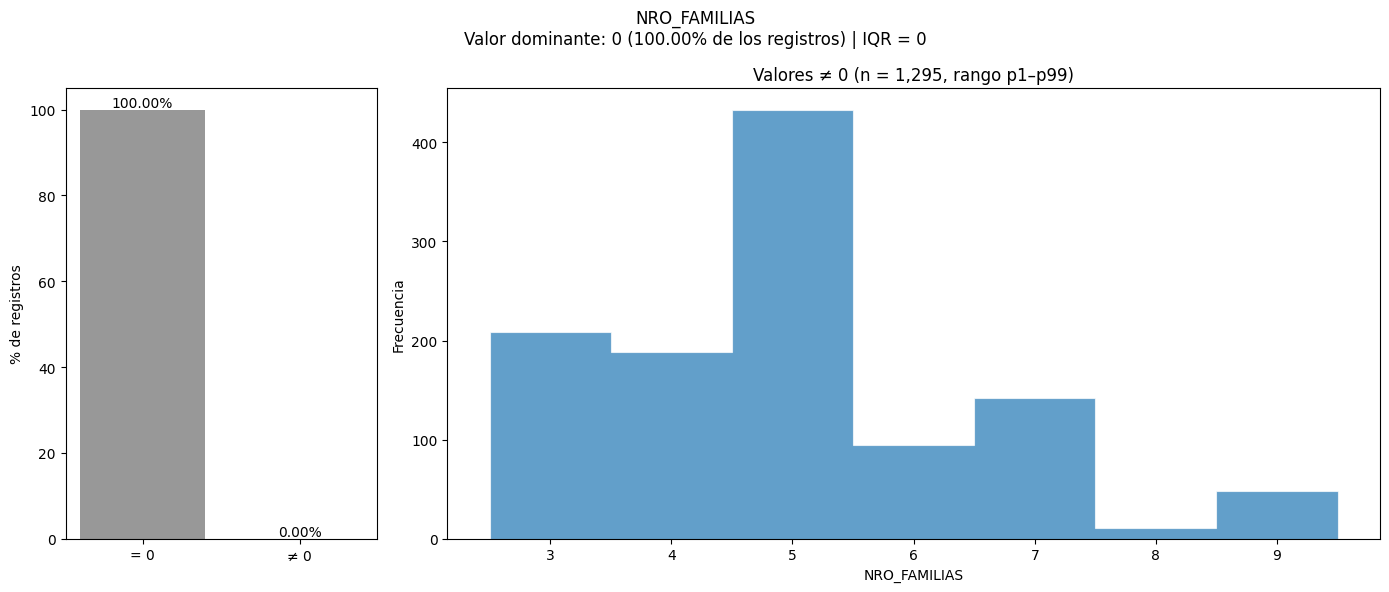

[OK] NRO_FAMILIAS guardado


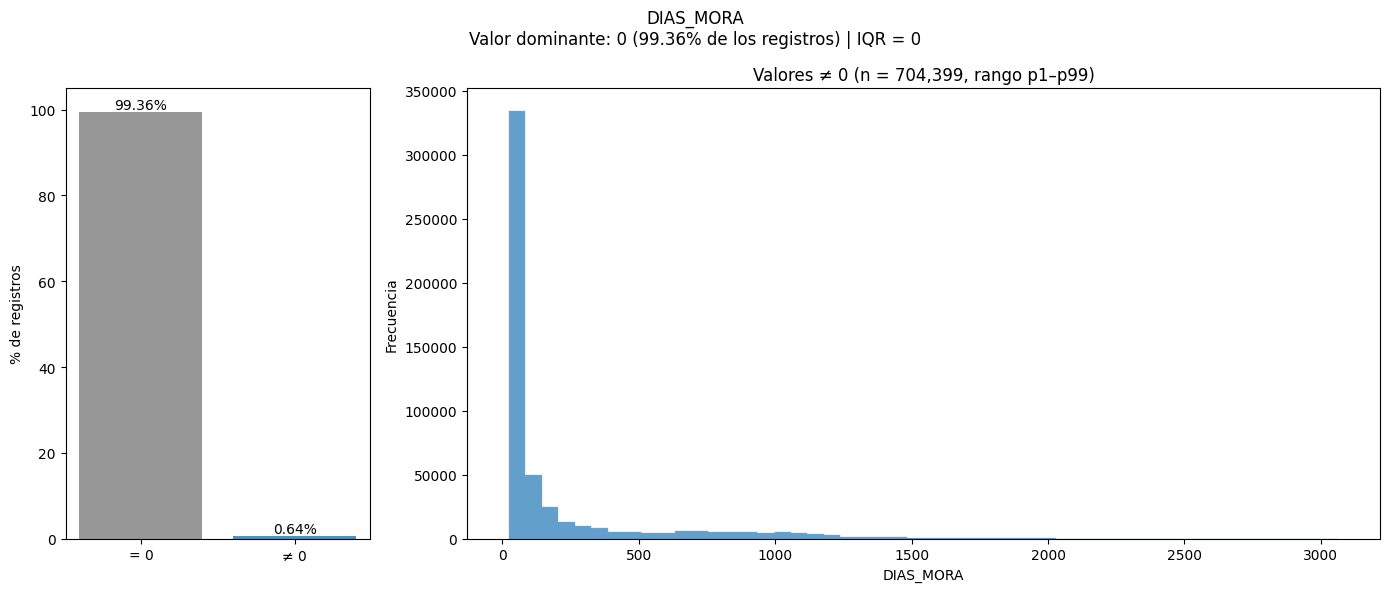

[OK] DIAS_MORA guardado


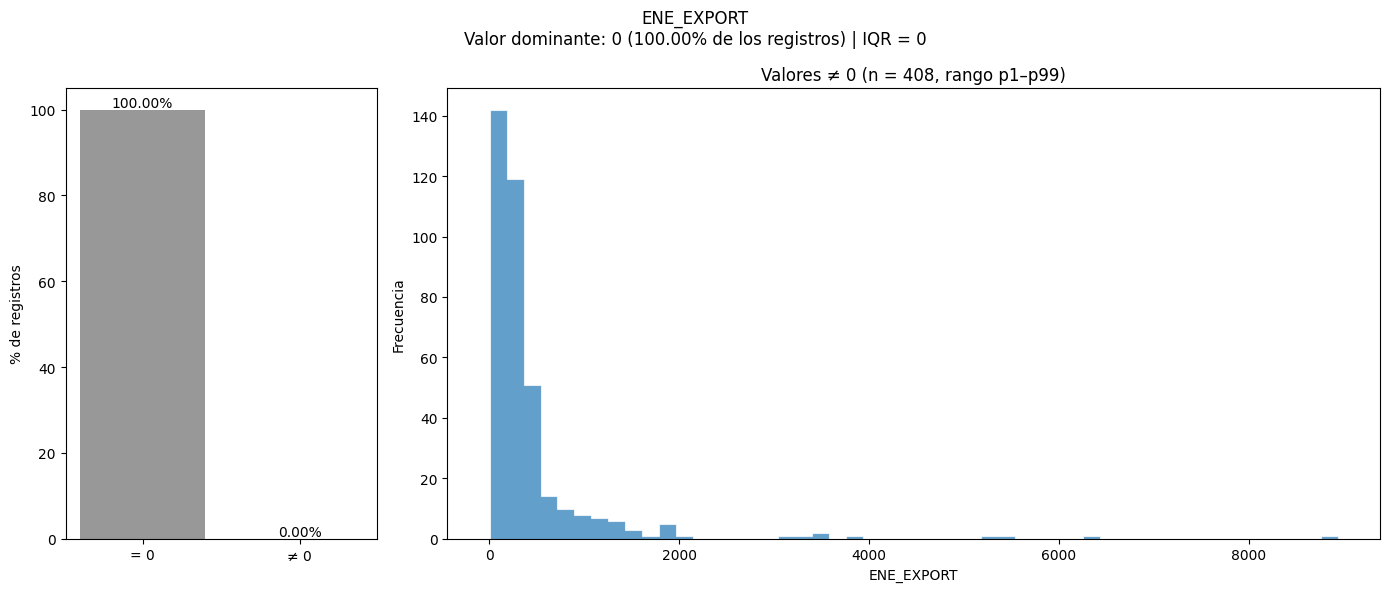

[OK] ENE_EXPORT guardado


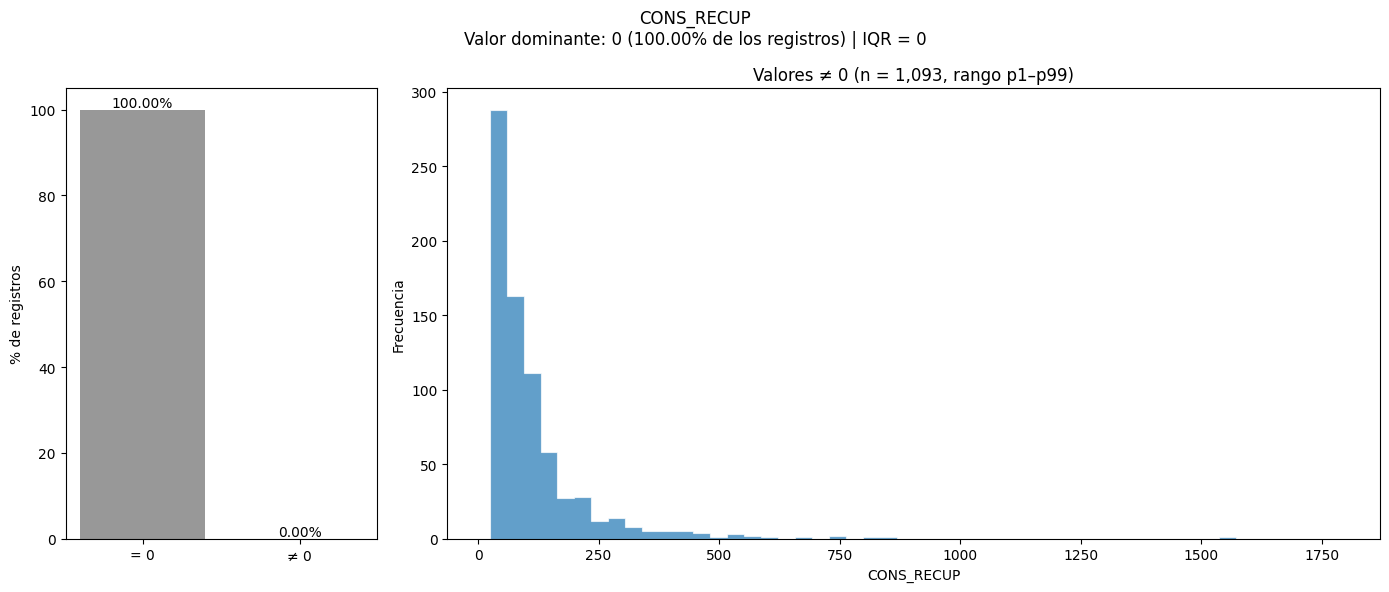

[OK] CONS_RECUP guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


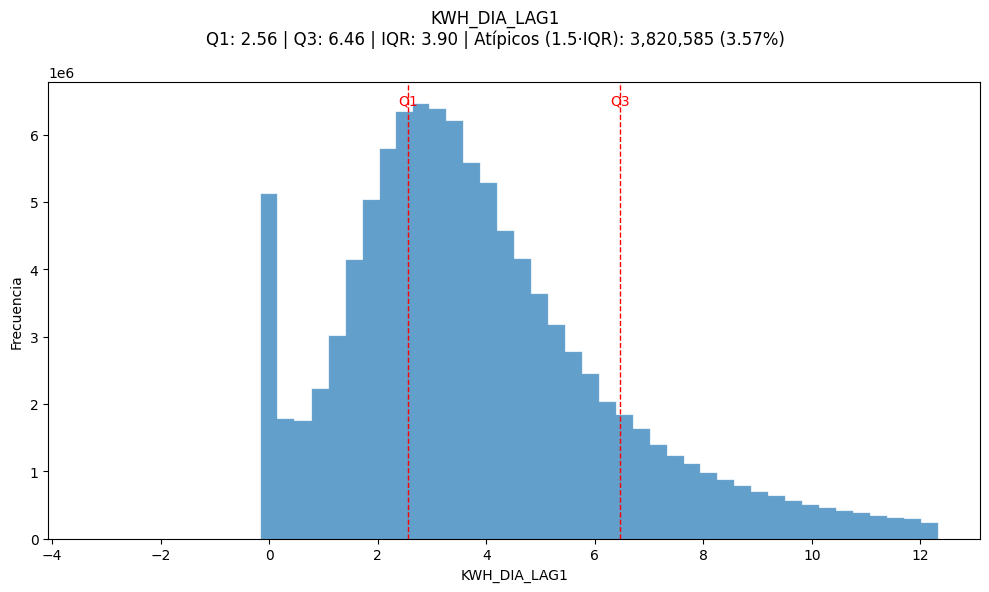

[OK] KWH_DIA_LAG1 guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


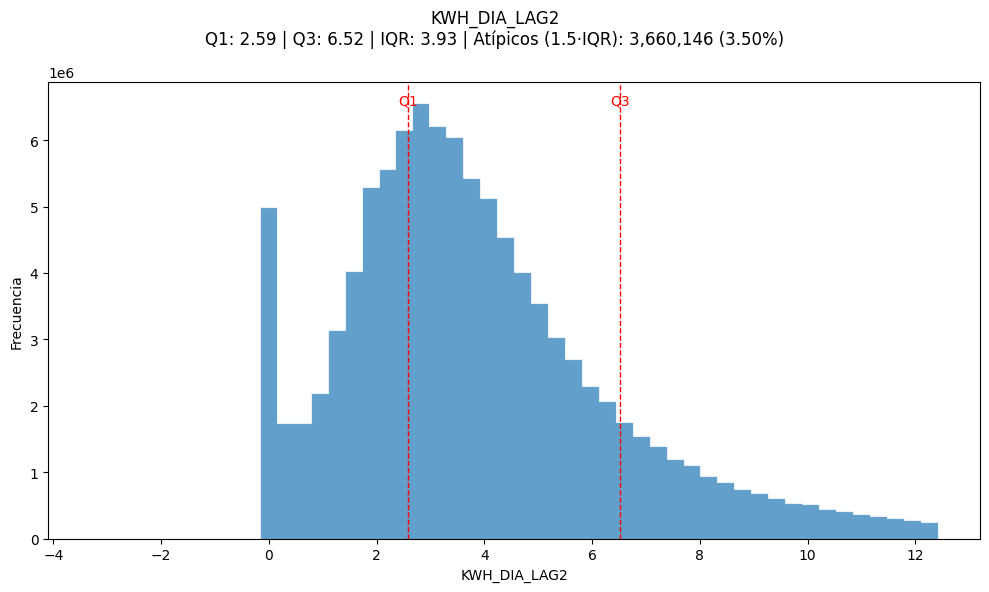

[OK] KWH_DIA_LAG2 guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


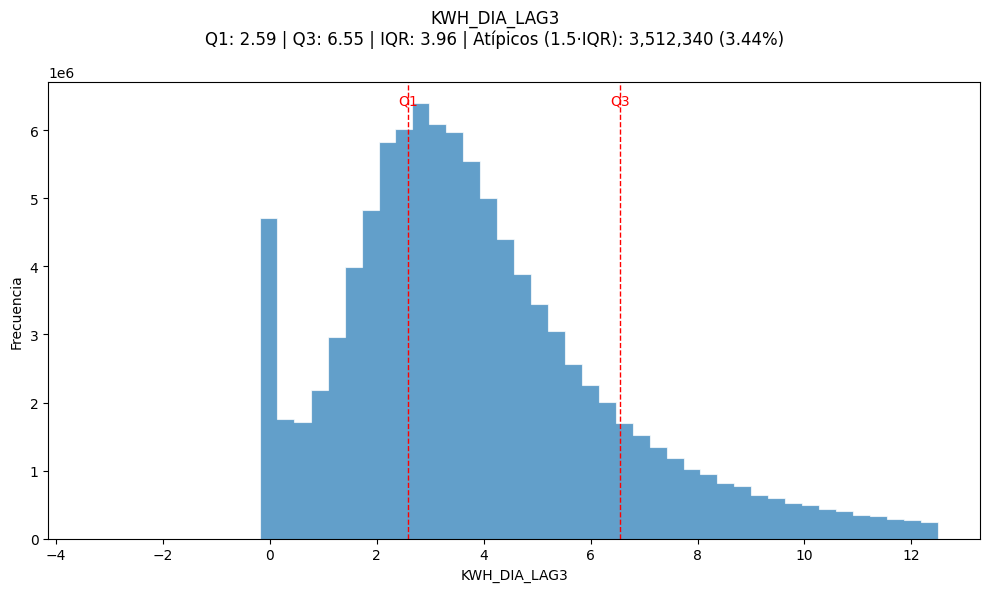

[OK] KWH_DIA_LAG3 guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


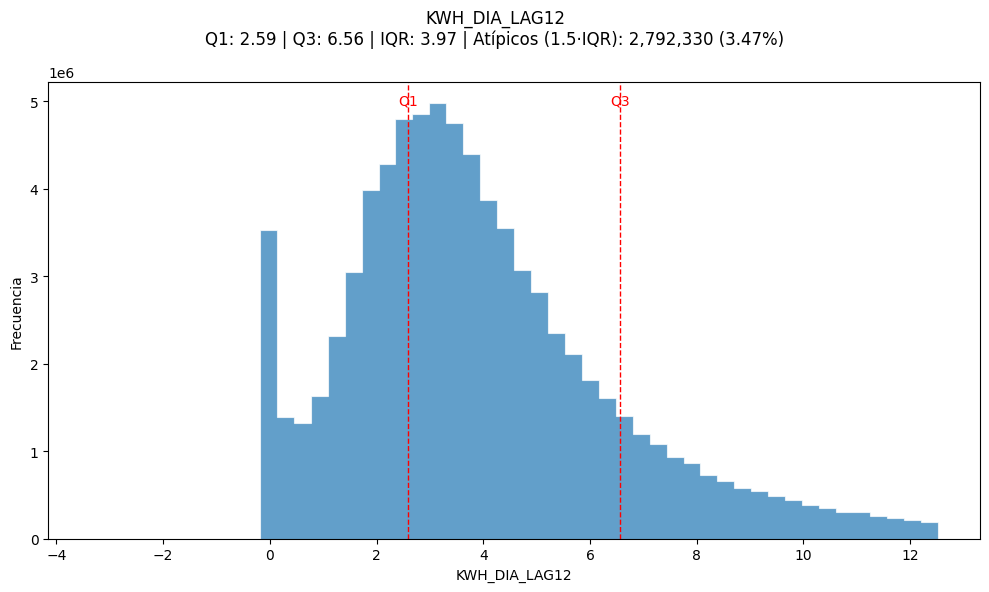

[OK] KWH_DIA_LAG12 guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


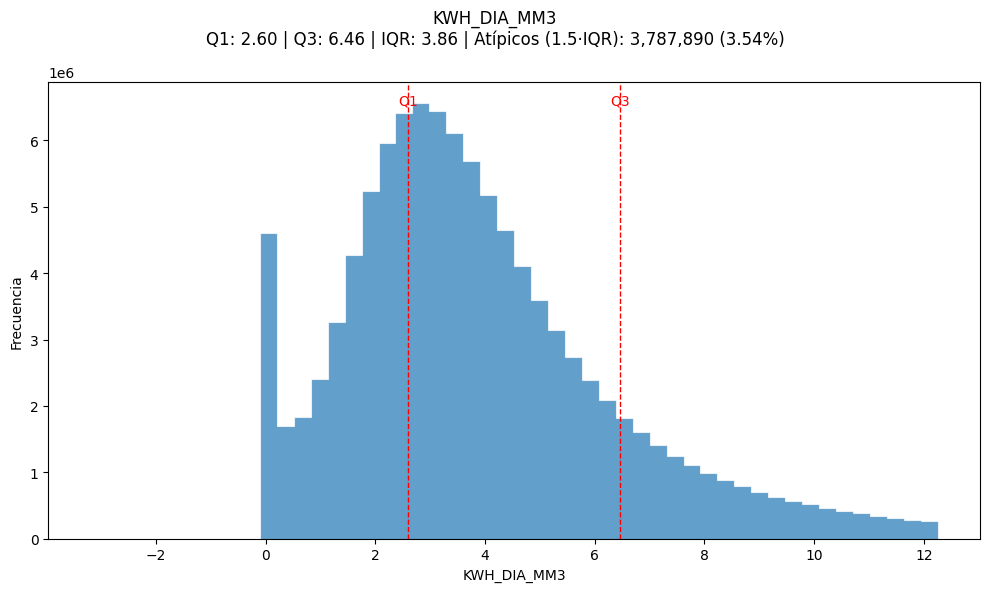

[OK] KWH_DIA_MM3 guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


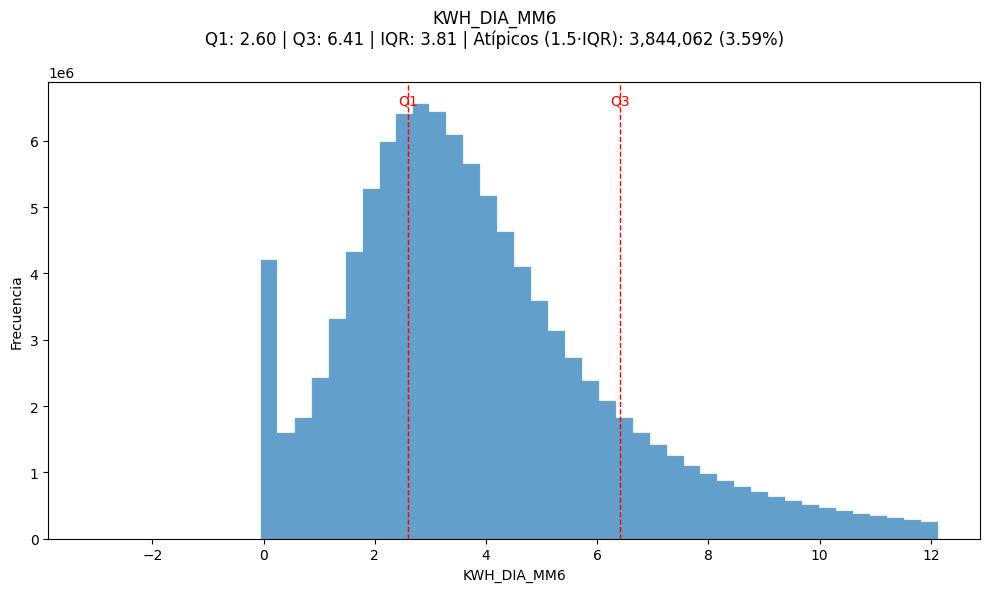

[OK] KWH_DIA_MM6 guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


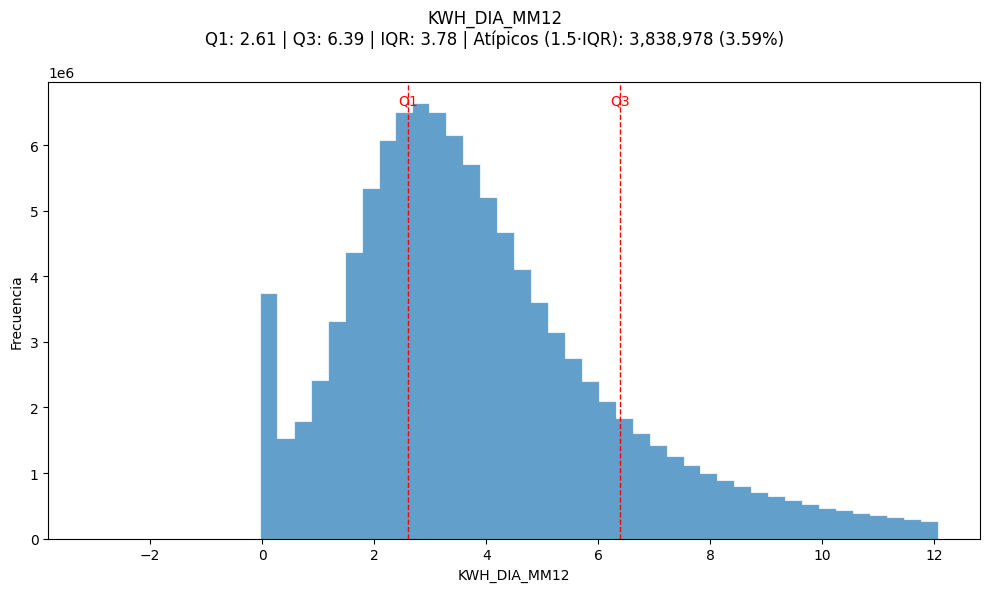

[OK] KWH_DIA_MM12 guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


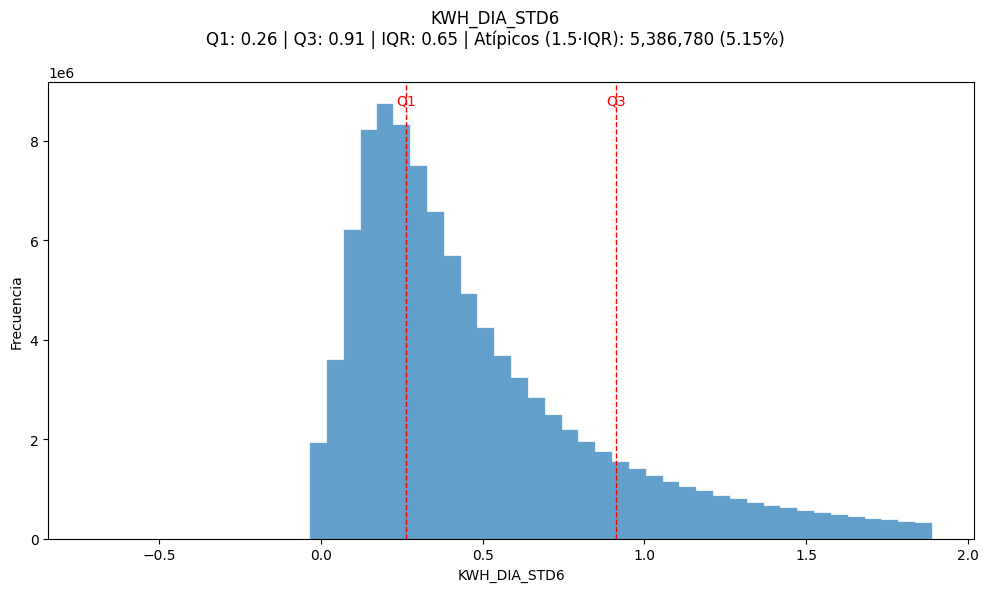

[OK] KWH_DIA_STD6 guardado


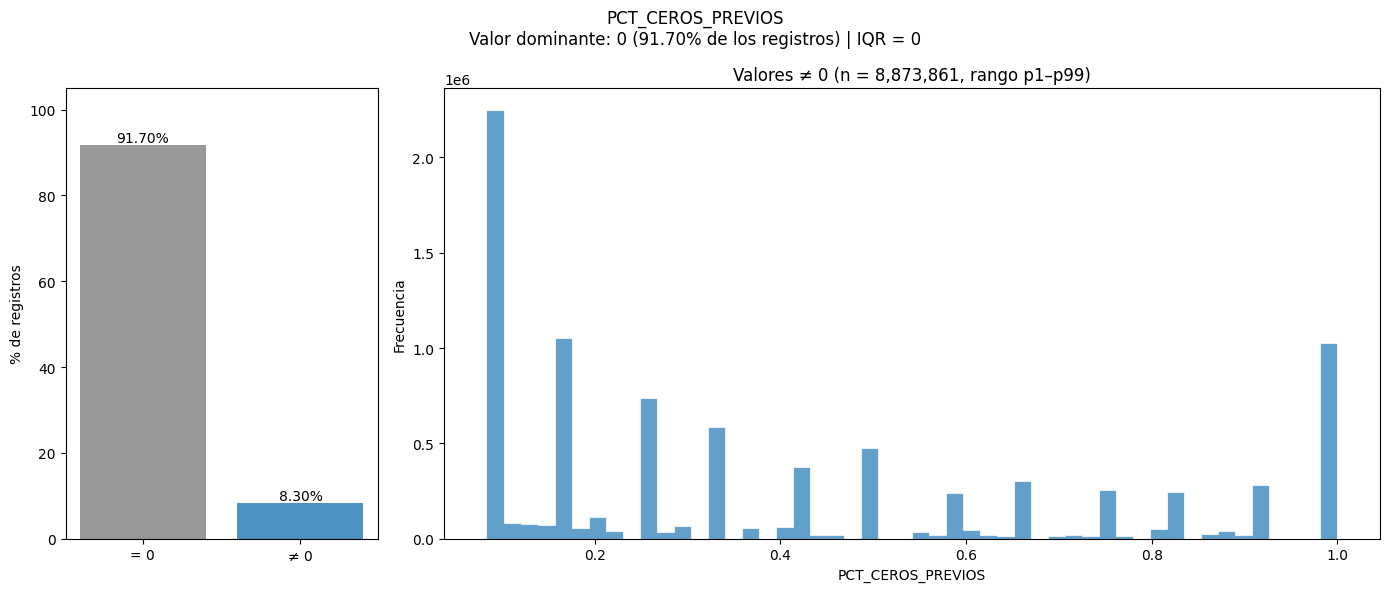

[OK] PCT_CEROS_PREVIOS guardado


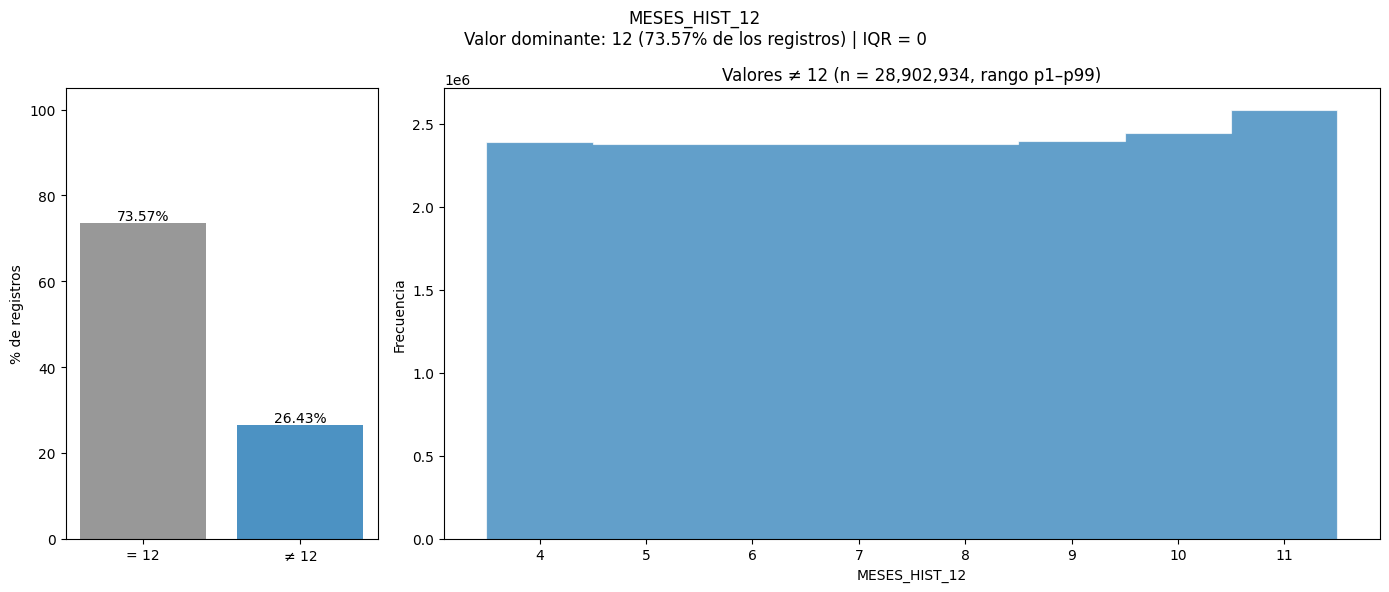

[OK] MESES_HIST_12 guardado


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


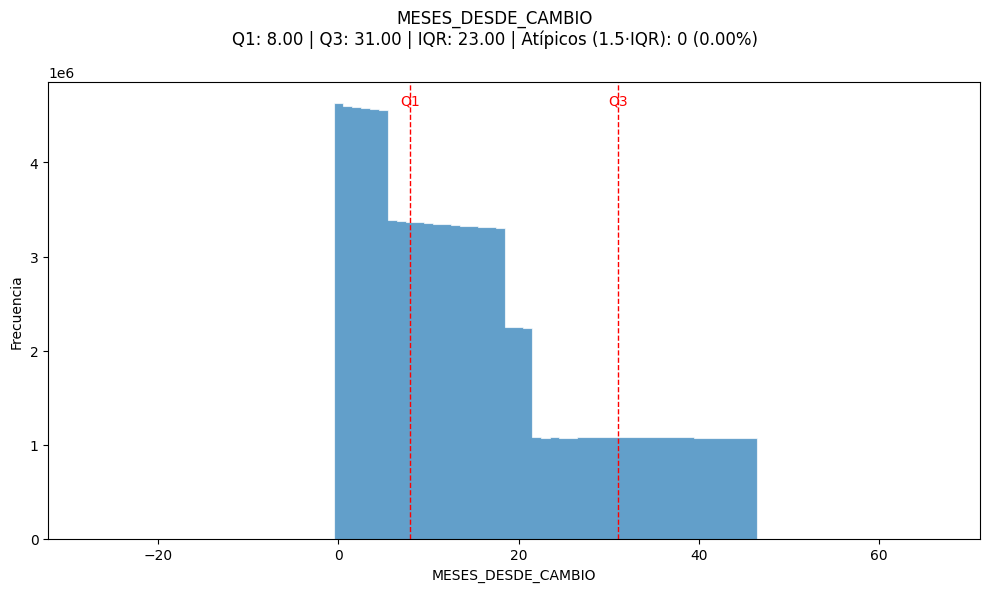

[OK] MESES_DESDE_CAMBIO guardado


In [34]:

output_folder = '/content/drive/MyDrive/Superintendencia/Distribución Datos/Var Cuantitativas'
os.makedirs(output_folder, exist_ok=True)

n_bins = 50
cols_discretas = ['DIAS_FACTURADOS', 'NRO_FAMILIAS', 'DIAS_MORA',
                  'MESES_HIST_12', 'MESES_DESDE_CAMBIO']

def histograma_dask(s, column, lo, hi):
    """Histograma calculado por Dask (devuelve objetos lazy)."""
    if lo == hi:
        lo, hi = lo - 0.5, hi + 0.5
    arr = s.to_dask_array()
    if column in cols_discretas and (np.ceil(hi) - np.floor(lo)) <= 100:
        bins = np.arange(np.floor(lo) - 0.5, np.ceil(hi) + 1.5, 1)
        return da.histogram(arr, bins=bins)
    return da.histogram(arr, bins=n_bins, range=(lo, hi))

def dibujar_hist(ax, counts, edges, column):
    ax.stairs(counts, edges, fill=True, alpha=0.7, edgecolor='white', linewidth=0.8)
    ax.set_xlabel(column)
    ax.set_ylabel('Frecuencia')

# 1. Cuantiles de todas las columnas en una sola pasada
cuantiles = df[cols_numericas].quantile([0.01, 0.25, 0.75, 0.99]).compute()

for column in cols_numericas:
    q01, Q1, Q3, q99 = cuantiles[column].values
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    s = df[column].dropna()
    n_total = s.count()
    n_outliers = ((s < lower_bound) | (s > upper_bound)).sum()

    if IQR > 0:
        # ---------- Caso normal: un solo histograma ----------
        counts, edges = histograma_dask(s, column, lower_bound, upper_bound)
        counts, n_total, n_outliers = dask.compute(counts, n_total, n_outliers)

        fig, ax = plt.subplots(figsize=(10, 6))
        dibujar_hist(ax, counts, np.asarray(edges), column)
        for x, label in [(Q1, 'Q1'), (Q3, 'Q3')]:
            ax.axvline(x, color='red', linestyle='--', linewidth=1)
            ax.text(x, ax.get_ylim()[1] * 0.95, label, color='red', ha='center')
        pct_out = 100 * n_outliers / n_total if n_total else 0
        fig.suptitle(
            f'{column}\nQ1: {Q1:,.2f} | Q3: {Q3:,.2f} | IQR: {IQR:,.2f} | '
            f'Atípicos (1.5·IQR): {n_outliers:,} ({pct_out:.2f}%)'
        )

    else:
        # ---------- Caso concentrado: un valor domina (IQR = 0) ----------
        moda = Q1
        s_resto = s[s != moda]
        n_resto, q_resto = dask.compute(s_resto.count(), s_resto.quantile([0.01, 0.99]))
        n_total = n_total.compute()
        pct_moda = 100 * (n_total - n_resto) / n_total if n_total else 0

        fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(14, 6),
                                         gridspec_kw={'width_ratios': [1, 3]})

        # Panel izquierdo: proporción del valor dominante vs. resto
        ax_l.bar([f'= {moda:g}', f'≠ {moda:g}'], [pct_moda, 100 - pct_moda],
                 color=['#7f7f7f', '#1f77b4'], alpha=0.8)
        for i, v in enumerate([pct_moda, 100 - pct_moda]):
            ax_l.text(i, v, f'{v:.2f}%', ha='center', va='bottom')
        ax_l.set_ylabel('% de registros')
        ax_l.set_ylim(0, 105)

        # Panel derecho: distribución de los valores distintos al dominante
        if n_resto > 0:
            lo, hi = q_resto.values  # p1–p99 del resto, para no aplastar con extremos
            counts, edges = histograma_dask(s_resto, column, lo, hi)
            counts = counts.compute()
            dibujar_hist(ax_r, counts, np.asarray(edges), column)
            ax_r.set_title(f'Valores ≠ {moda:g} (n = {n_resto:,}, rango p1–p99)')
        else:
            ax_r.text(0.5, 0.5, 'Variable constante', ha='center', va='center',
                      transform=ax_r.transAxes)
            ax_r.set_axis_off()

        fig.suptitle(
            f'{column}\nValor dominante: {moda:g} ({pct_moda:.2f}% de los registros) | IQR = 0'
        )

    fig.tight_layout()
    fig.savefig(os.path.join(output_folder, f'hist_{column}.png'), dpi=120)
    plt.show()
    plt.close(fig)
    print(f'[OK] {column} guardado')



### Variables Cualitativas

In [30]:
df[cols_categoricas].describe().compute().T

,count,mean,std,min,25%,50%,75%,max
MES,"109,345,545.00",6.52,3.45,1.00,4.00,7.00,10.00,12.00
ID_MERCADO,"109,345,545.00",176.00,0.00,176.00,176.00,176.00,176.00,176.00
DANE_NIU,"109,345,545.00","11,001,000.00",0.00,"11,001,000.00","11,001,000.00","11,001,000.00","11,001,000.00","11,001,000.00"
UBICACION,"109,345,545.00",1.99,0.08,1.00,2.00,2.00,2.00,3.00
ESTRATO_SECTOR,"109,345,545.00",2.85,1.13,1.00,2.00,3.00,4.00,6.00
NIVEL_TENSION,"109,345,545.00",1.00,0.00,1.00,1.00,1.00,1.00,2.00
TIPO_CONEXION,"109,345,545.00",2.00,0.00,2.00,2.00,2.00,2.00,2.00
AUTOGENERADOR,"109,345,545.00",3.00,0.01,1.00,3.00,3.00,3.00,3.00
CAMBIO_TRAFO,"109,345,545.00",0.00,0.03,0.00,0.00,0.00,0.00,1.00
CAMBIO_ESTRATO,"109,345,545.00",0.00,0.01,0.00,0.00,0.00,0.00,1.00


In [32]:
nulos = df.isnull().sum().compute()
total = len(df)
tabla_nulos = pd.DataFrame({
    'nulos': nulos,
    'pct_nulos': (nulos / total * 100).round(2)
}).sort_values('pct_nulos', ascending=False)
tabla_nulos


,nulos,pct_nulos
KWH_DIA_LAG12,28902934,26.43
KWH_DIA_LAG3,7338831,6.71
KWH_DIA_LAG2,4903734,4.48
KWH_DIA_STD6,4819089,4.41
MESES_DESDE_CAMBIO,4705076,4.30
KWH_DIA_LAG1,2459404,2.25
KWH_DIA_MM3,2418774,2.21
PCT_CEROS_PREVIOS,2402677,2.20
KWH_DIA_MM12,2402677,2.20
KWH_DIA_MM6,2409324,2.20


=== Estadísticos descriptivos ===


,count,mean,std,min,25%,50%,75%,max
KWH_DIA,"109,345,545.00",4.62,10.75,0.00,2.52,4.07,6.28,"39,427.10"
PROM_SEM_BENCHMARK,"109,345,545.00",138.17,"1,613.58",0.00,74.00,116.00,185.00,"16,235,314.00"
BENCH_KWH_DIA,"109,345,545.00",4.56,57.48,0.00,2.43,3.90,6.31,"579,832.64"



=== Cuantiles (incluye p99 y p99.9) ===


,0.01,0.25,0.50,0.75,0.99,1.00
KWH_DIA,0.00,2.52,4.07,6.28,23.17,154.66
PROM_SEM_BENCHMARK,0.00,74.00,116.00,181.00,715.00,"5,000.00"
BENCH_KWH_DIA,0.00,2.42,3.86,6.00,23.33,178.57



=== % de registros en 0 ===
KWH_DIA              3.19
PROM_SEM_BENCHMARK   4.02
BENCH_KWH_DIA        4.02

=== Registros con kWh/día > 100 ===
KWH_DIA          102844
BENCH_KWH_DIA    119122

=== Chequeo de unidades (deberían ser del mismo orden si el benchmark es kWh/mes) ===
CONSUMO_KWH          140.34
PROM_SEM_BENCHMARK   138.17


/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


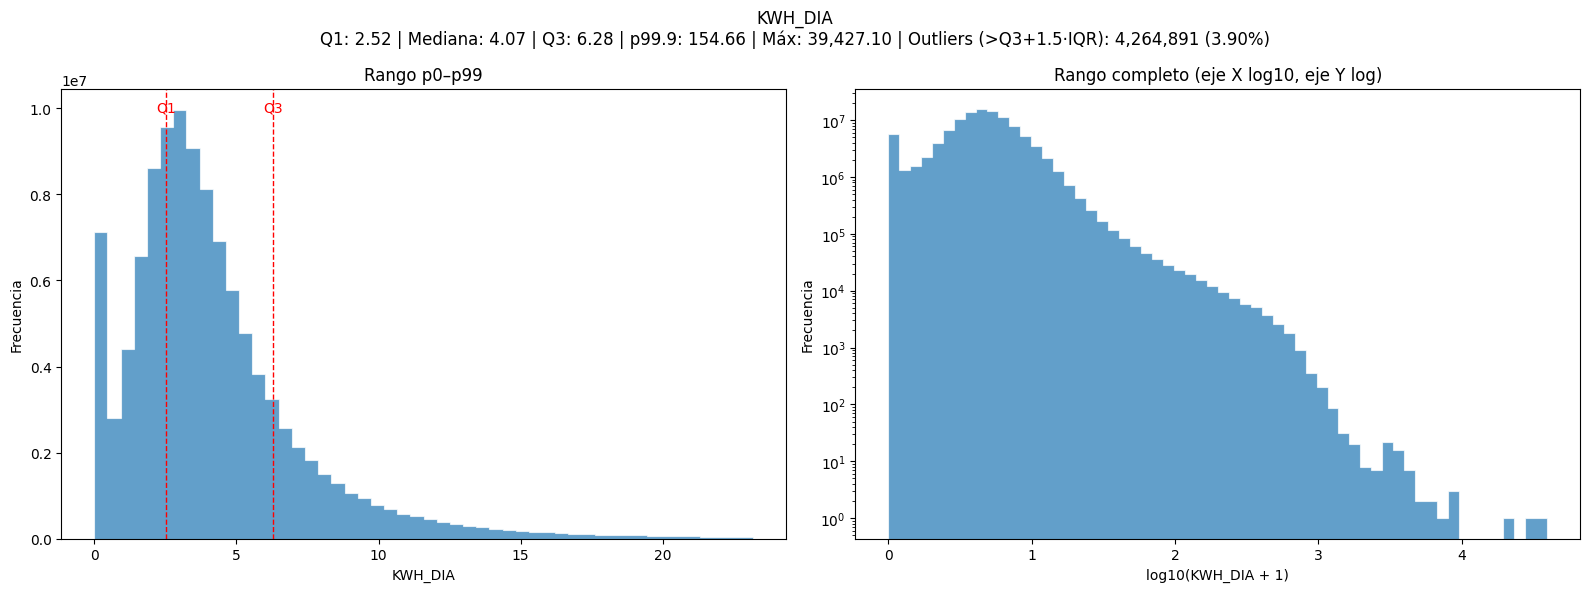

/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


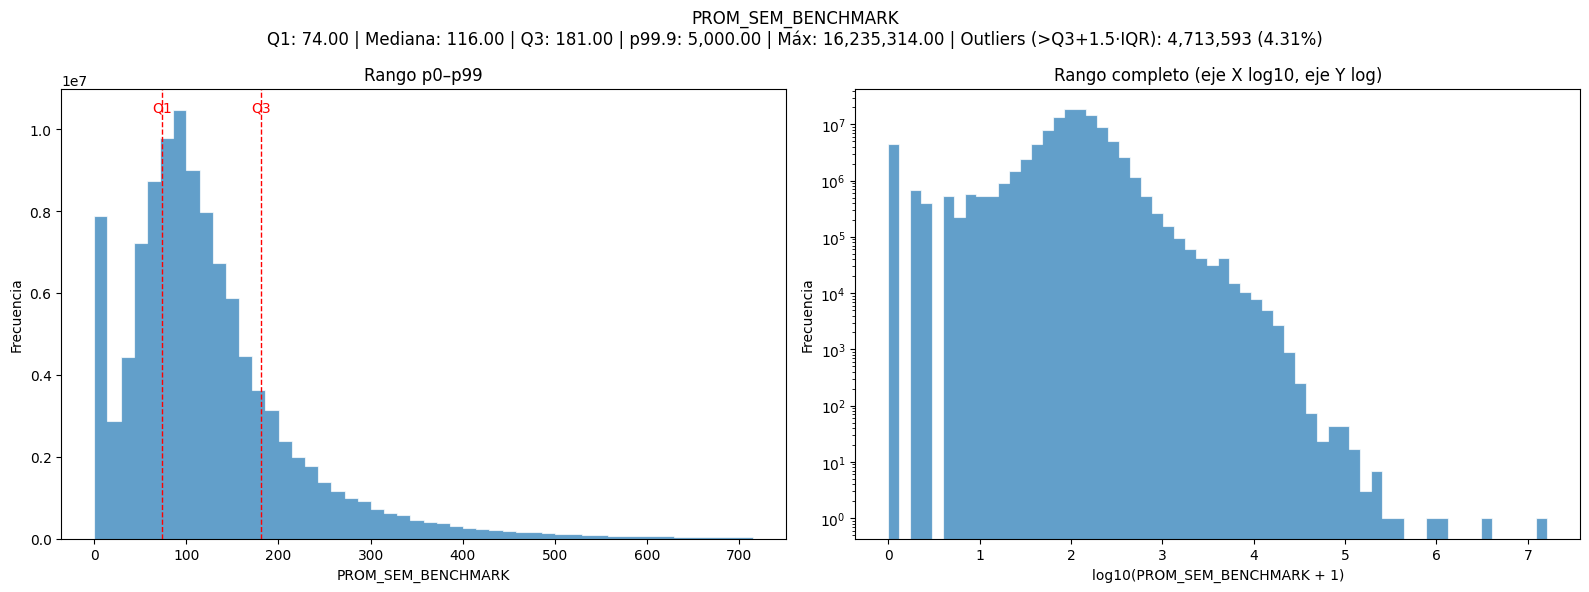

/usr/local/lib/python3.13/dist-packages/dask/_expr.py:1267: UserWarning: Computing mixed collections that are backed by HighlevelGraphs/dicts and Expressions. This forces Expressions to be materialized. It is recommended to use only one type and separate the dask.compute calls if necessary.
  warnings.warn(


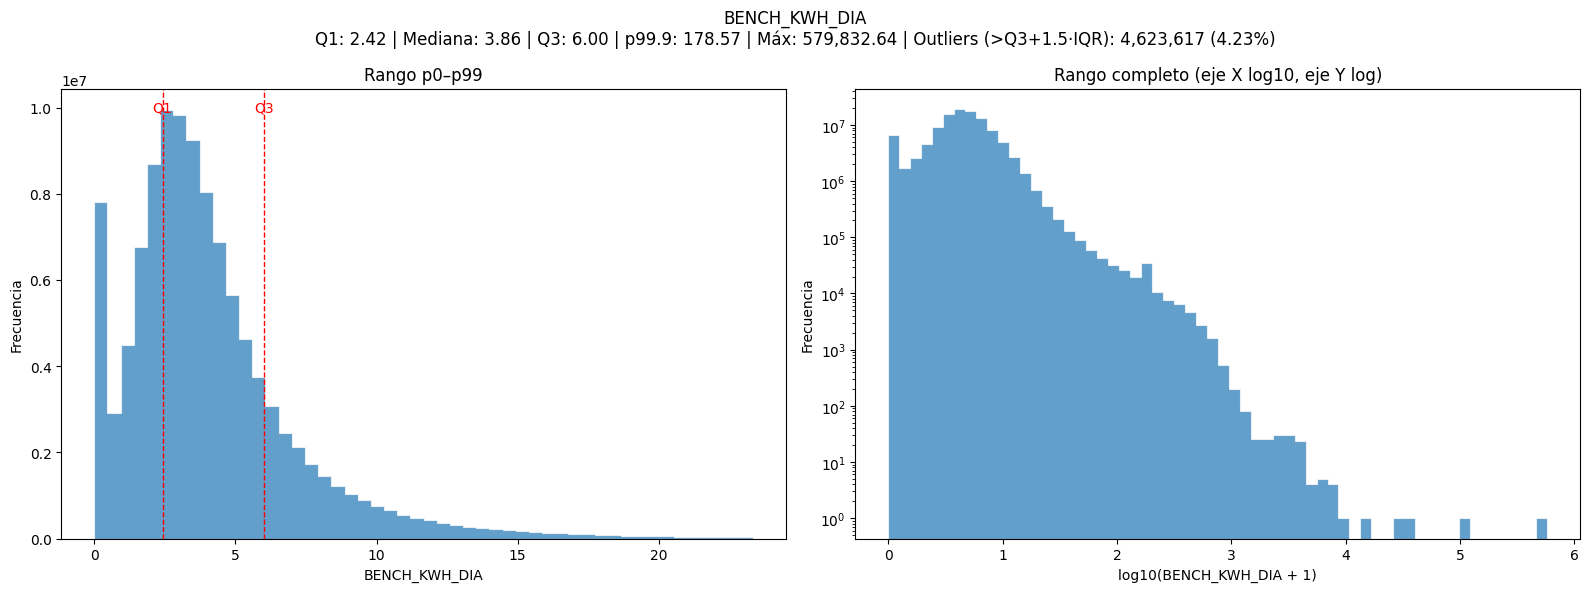

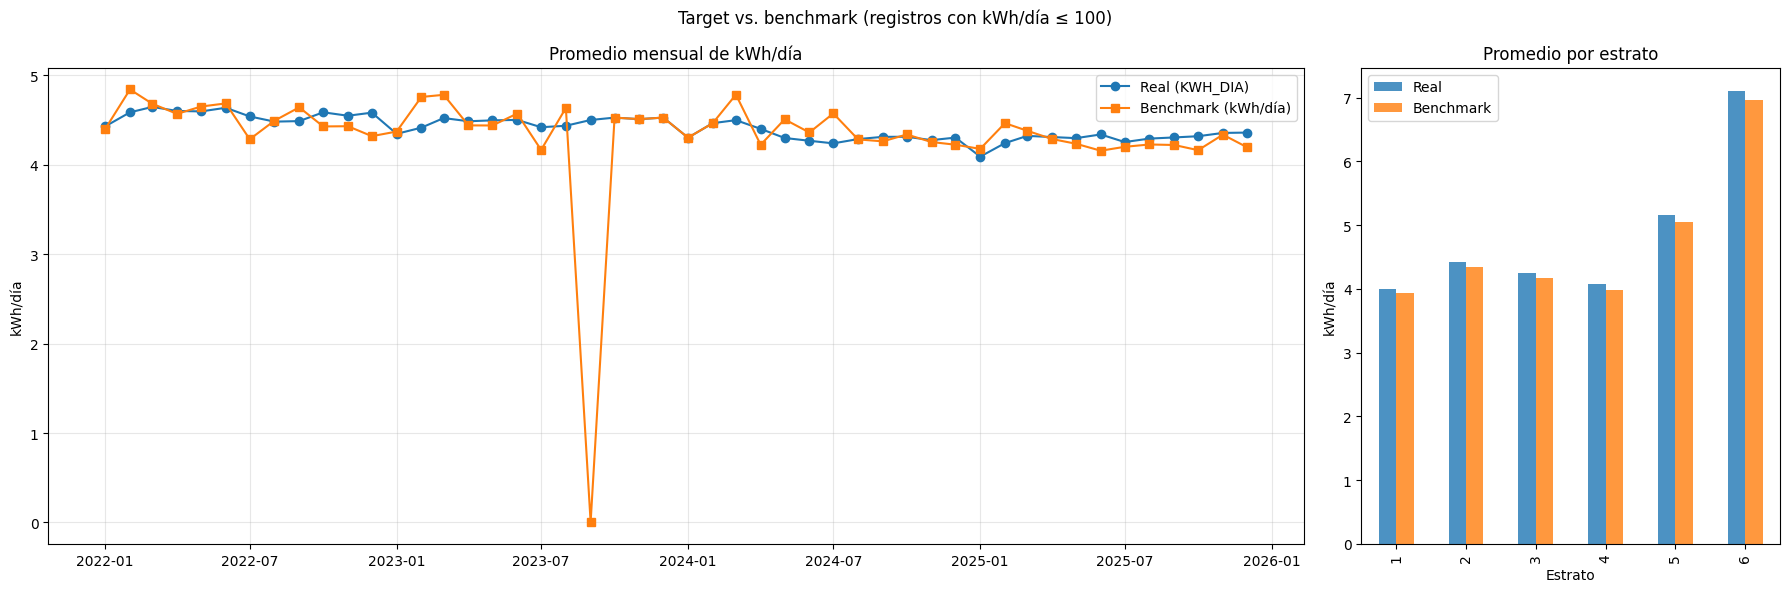

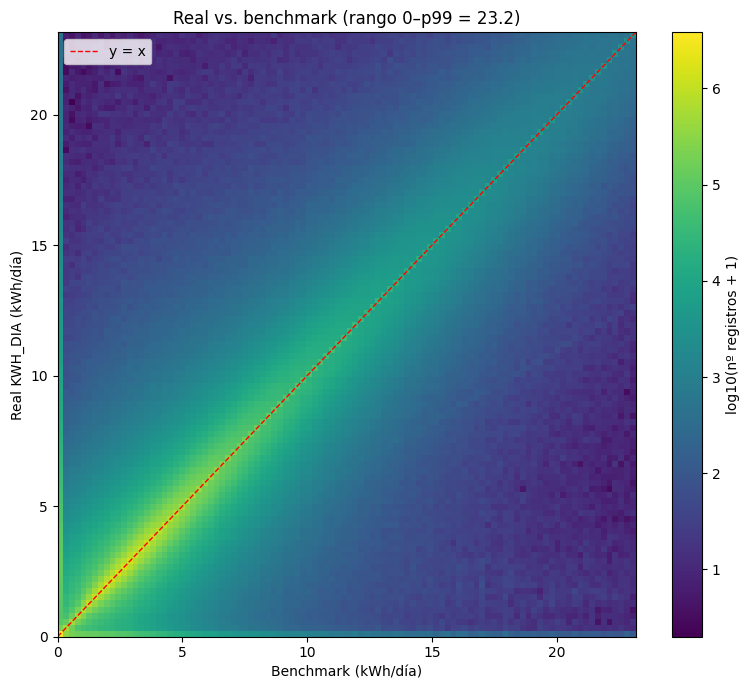

=== Línea base: PROM_SEM_BENCHMARK (kWh/día) como predicción de KWH_DIA ===


,n,MAE,RMSE,R2
Todos los registros,"109,345,545.00",0.81,57.11,-27.20
kWh/día ≤ 100,"109,214,551.00",0.74,1.72,0.85


In [33]:
# ============================================================
# Análisis del target (KWH_DIA) y del benchmark (PROM_SEM_BENCHMARK)
# ============================================================
output_folder_obj = '/content/drive/MyDrive/Superintendencia/Distribución Datos/Var Objetivo'
os.makedirs(output_folder_obj, exist_ok=True)

UMBRAL_KWH_DIA = 100  # umbral físico tentativo para un hogar (≈3.000 kWh/mes)

# Benchmark llevado a kWh/día con los mismos días facturados del target
df['BENCH_KWH_DIA'] = df['PROM_SEM_BENCHMARK'] / df['DIAS_FACTURADOS']
vars_obj = ['KWH_DIA', 'PROM_SEM_BENCHMARK', 'BENCH_KWH_DIA']

# ------------------------------------------------------------
# 1. Estadísticos en una sola pasada
# ------------------------------------------------------------
desc, cuant, pct_ceros, n_extremos, medias_unid = dask.compute(
    df[vars_obj].describe(),
    df[vars_obj].quantile([0.01, 0.25, 0.5, 0.75, 0.99, 0.999]),
    (df[vars_obj] == 0).mean() * 100,
    (df[['KWH_DIA', 'BENCH_KWH_DIA']] > UMBRAL_KWH_DIA).sum(),
    df[['CONSUMO_KWH', 'PROM_SEM_BENCHMARK']].mean(),
)

print("=== Estadísticos descriptivos ===")
display(desc.T)
print("\n=== Cuantiles (incluye p99 y p99.9) ===")
display(cuant.T)
print("\n=== % de registros en 0 ===")
print(pct_ceros.round(2).to_string())
print(f"\n=== Registros con kWh/día > {UMBRAL_KWH_DIA} ===")
print(n_extremos.to_string())
print("\n=== Chequeo de unidades (deberían ser del mismo orden si el benchmark es kWh/mes) ===")
print(medias_unid.round(2).to_string())

# ------------------------------------------------------------
# 2. Histogramas: rango típico (p0–p99) y escala logarítmica (rango completo)
# ------------------------------------------------------------
for column in vars_obj:
    Q1, Q3 = cuant.loc[0.25, column], cuant.loc[0.75, column]
    p99 = cuant.loc[0.99, column]
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    vmax = desc.loc['max', column]

    s = df[column].dropna().clip(lower=0)
    counts_lin, edges_lin = histograma_dask(s, column, 0, p99)
    counts_log, edges_log = da.histogram(da.log10(s.to_dask_array() + 1),
                                         bins=60, range=(0, np.log10(vmax + 1)))
    n_out = (s > upper_bound).sum()
    counts_lin, counts_log, n_out, n_tot = dask.compute(counts_lin, counts_log, n_out, s.count())

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    dibujar_hist(ax1, counts_lin, np.asarray(edges_lin), column)
    for x, label in [(Q1, 'Q1'), (Q3, 'Q3')]:
        ax1.axvline(x, color='red', linestyle='--', linewidth=1)
        ax1.text(x, ax1.get_ylim()[1] * 0.95, label, color='red', ha='center')
    ax1.set_title('Rango p0–p99')

    dibujar_hist(ax2, counts_log, np.asarray(edges_log), f'log10({column} + 1)')
    ax2.set_yscale('log')
    ax2.set_title('Rango completo (eje X log10, eje Y log)')

    fig.suptitle(f'{column}\nQ1: {Q1:,.2f} | Mediana: {cuant.loc[0.5, column]:,.2f} | Q3: {Q3:,.2f} | '
                 f'p99.9: {cuant.loc[0.999, column]:,.2f} | Máx: {vmax:,.2f} | '
                 f'Outliers (>Q3+1.5·IQR): {n_out:,} ({100*n_out/n_tot:.2f}%)')
    fig.tight_layout()
    fig.savefig(os.path.join(output_folder_obj, f'hist_{column}.png'), dpi=120)
    plt.show(); plt.close(fig)

# ------------------------------------------------------------
# 3. Evolución mensual y comparación por estrato (sin extremos)
# ------------------------------------------------------------
df_ok = df[(df['KWH_DIA'] <= UMBRAL_KWH_DIA) & (df['BENCH_KWH_DIA'] <= UMBRAL_KWH_DIA)]

serie_mes, por_estrato = dask.compute(
    df_ok.groupby('PERIODO')[['KWH_DIA', 'BENCH_KWH_DIA']].mean(),
    df_ok.groupby('ESTRATO_SECTOR')[['KWH_DIA', 'BENCH_KWH_DIA']].mean(),
)
serie_mes = serie_mes.sort_index()
por_estrato = por_estrato.sort_index()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [3, 1]})
ax1.plot(serie_mes.index, serie_mes['KWH_DIA'], marker='o', label='Real (KWH_DIA)')
ax1.plot(serie_mes.index, serie_mes['BENCH_KWH_DIA'], marker='s', label='Benchmark (kWh/día)')
ax1.set_title('Promedio mensual de kWh/día')
ax1.set_ylabel('kWh/día'); ax1.legend(); ax1.grid(alpha=0.3)

por_estrato.plot(kind='bar', ax=ax2, alpha=0.8)
ax2.set_title('Promedio por estrato'); ax2.set_xlabel('Estrato'); ax2.set_ylabel('kWh/día')
ax2.legend(['Real', 'Benchmark'])
fig.suptitle(f'Target vs. benchmark (registros con kWh/día ≤ {UMBRAL_KWH_DIA})')
fig.tight_layout()
fig.savefig(os.path.join(output_folder_obj, 'serie_mensual_y_estrato.png'), dpi=120)
plt.show(); plt.close(fig)

# ------------------------------------------------------------
# 4. Mapa de calor real vs. benchmark (histograma 2D por partición)
# ------------------------------------------------------------
lim = float(cuant.loc[0.99, 'KWH_DIA'])
edges2d = np.linspace(0, lim, 101)

def hist2d_particion(p):
    p = p[['BENCH_KWH_DIA', 'KWH_DIA']].dropna()
    h, _, _ = np.histogram2d(p['BENCH_KWH_DIA'], p['KWH_DIA'], bins=[edges2d, edges2d])
    return h

partes = df[['BENCH_KWH_DIA', 'KWH_DIA']].to_delayed()
h2d = dask.delayed(sum)([dask.delayed(hist2d_particion)(p) for p in partes]).compute()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.pcolormesh(edges2d, edges2d, np.log10(h2d.T + 1), cmap='viridis')
ax.plot([0, lim], [0, lim], color='red', linestyle='--', linewidth=1, label='y = x')
ax.set_xlabel('Benchmark (kWh/día)'); ax.set_ylabel('Real KWH_DIA (kWh/día)')
ax.set_title(f'Real vs. benchmark (rango 0–p99 = {lim:.1f})')
fig.colorbar(im, ax=ax, label='log10(nº registros + 1)'); ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(output_folder_obj, 'real_vs_benchmark.png'), dpi=120)
plt.show(); plt.close(fig)

# ------------------------------------------------------------
# 5. Métricas de la línea base (benchmark como predicción)
# ------------------------------------------------------------
def metricas_benchmark(d):
    d = d[['KWH_DIA', 'BENCH_KWH_DIA']].dropna()
    y, yhat = d['KWH_DIA'], d['BENCH_KWH_DIA']
    e = y - yhat
    mae, mse, ymean, y2mean, n = dask.compute(e.abs().mean(), (e ** 2).mean(),
                                              y.mean(), (y ** 2).mean(), y.count())
    return {'n': n, 'MAE': mae, 'RMSE': np.sqrt(mse), 'R2': 1 - mse / (y2mean - ymean ** 2)}

tabla_metricas = pd.DataFrame({
    'Todos los registros': metricas_benchmark(df),
    f'kWh/día ≤ {UMBRAL_KWH_DIA}': metricas_benchmark(df_ok),
}).T
print("=== Línea base: PROM_SEM_BENCHMARK (kWh/día) como predicción de KWH_DIA ===")
display(tabla_metricas)
